# 03 因子分析

## 目标
- IC分析：Rank IC / Pearson IC
- IC_IR、IC>0胜率等统计
- 分层回测：按因子值分组观察收益单调性
- 因子相关性分析
- 筛选有效因子

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('✓ 依赖加载完毕')

✓ 依赖加载完毕


## 2. 加载数据

In [2]:
ret_df = pd.read_csv('data/ret_df.csv', index_col=0, parse_dates=True)
# dtype={1: str} 确保 ticker 不被读成整数
factor_wide = pd.read_csv('data/factor_wide.csv', index_col=[0, 1], dtype={1: str})
# 用 from_arrays 重建 MultiIndex（兼容 pandas 2.x）
factor_wide.index = pd.MultiIndex.from_arrays([
    pd.to_datetime(factor_wide.index.get_level_values(0)),
    factor_wide.index.get_level_values(1)
], names=['date', 'ticker'])
factor_meta = pd.read_csv('data/factor_meta.csv')

factor_names = factor_wide.columns.tolist()
date_min = factor_wide.index.get_level_values('date').min()
date_max = factor_wide.index.get_level_values('date').max()

print(f'收益率矩阵: {ret_df.shape}')
print(f'因子宽表: {factor_wide.shape}')
print(f'因子数量: {len(factor_names)}')
print(f'日期范围: {date_min} ~ {date_max}')

收益率矩阵: (716, 40)
因子宽表: (28680, 28)
因子数量: 28
日期范围: 2023-01-03 00:00:00 ~ 2025-12-31 00:00:00


## 3. IC分析框架

In [3]:
def compute_ic_series(factor_name, factor_wide, ret_df, method='rank'):
    """
    计算一个因子的IC时间序列
    method: 'rank' (Spearman Rank IC) 或 'pearson' (Pearson IC)
    """
    ic_list = []
    dates = factor_wide.index.get_level_values('date').unique()
    
    for date in dates:
        try:
            # MultiIndex: .loc[date] 返回 index=ticker 的 DataFrame
            f_cross = factor_wide.loc[date][factor_name]
            r_cross = ret_df.loc[date]
            
            # 对齐ticker
            common = f_cross.index.intersection(r_cross.index)
            if len(common) < 10:
                continue
            
            f_vals = f_cross[common].values.astype(float)
            r_vals = r_cross[common].values.astype(float)
            
            # 移除inf和nan
            mask = np.isfinite(f_vals) & np.isfinite(r_vals)
            if mask.sum() < 10:
                continue
            
            f_vals = f_vals[mask]
            r_vals = r_vals[mask]
            
            if method == 'rank':
                ic, _ = stats.spearmanr(f_vals, r_vals)
            else:
                ic, _ = stats.pearsonr(f_vals, r_vals)
            
            ic_list.append({'date': date, 'ic': ic})
        except Exception as e:
            continue
    
    if len(ic_list) == 0:
        return pd.Series(dtype=float)
    return pd.DataFrame(ic_list).set_index('date')['ic']

In [4]:
%%time

# 计算所有因子的Rank IC序列
ic_results = {}

for fname in factor_names:
    ic_series = compute_ic_series(fname, factor_wide, ret_df, method='rank')
    if len(ic_series) > 0:
        ic_results[fname] = ic_series

print(f'✓ IC计算完成: {len(ic_results)}/{len(factor_names)} 个因子有效')

✓ IC计算完成: 28/28 个因子有效
CPU times: total: 23.9 s
Wall time: 24.1 s


In [5]:
# ===== IC统计汇总 =====
ic_summary = []

for fname, ic_series in ic_results.items():
    ic_mean = ic_series.mean()
    ic_std = ic_series.std()
    ic_ir = ic_mean / (ic_std + 1e-10)
    ic_winrate = (ic_series > 0).mean()
    ic_tstat = ic_mean / (ic_std / np.sqrt(len(ic_series)) + 1e-10)
    
    cat = factor_meta[factor_meta['factor_name'] == fname]['category'].values
    cat = cat[0] if len(cat) > 0 else 'unknown'
    
    ic_summary.append({
        'factor': fname,
        'category': cat,
        'IC_mean': ic_mean,
        'IC_std': ic_std,
        'IC_IR': ic_ir,
        'IC_winrate': ic_winrate,
        'abs_IC_IR': abs(ic_ir),
        'n_obs': len(ic_series),
    })

ic_df = pd.DataFrame(ic_summary).sort_values('abs_IC_IR', ascending=False)
ic_df = ic_df.reset_index(drop=True)

### 3.1 IC分析结果总览

In [6]:
print('=' * 90)
print('因子IC分析汇总 (按 |IC_IR| 排序)')
print('=' * 90)
print(f'{"因子":<22s} {"类别":>10s} {"IC均值":>8s} {"IC_IR":>8s} {"胜率":>8s} {"|IC_IR|":>8s} {"评级":>6s}')
print('-' * 90)

for _, row in ic_df.iterrows():
    rating = '★★★' if row['abs_IC_IR'] > 0.5 else ('★★' if row['abs_IC_IR'] > 0.25 else '★')
    if row['abs_IC_IR'] < 0.1:
        rating = '✗'
    print(f'{row["factor"]:<22s} {row["category"]:>10s} {row["IC_mean"]:>8.4f} {row["IC_IR"]:>8.3f} {row["IC_winrate"]:>7.1%} {row["abs_IC_IR"]:>8.3f} {rating:>6s}')

因子IC分析汇总 (按 |IC_IR| 排序)
因子                             类别     IC均值    IC_IR       胜率  |IC_IR|     评级
------------------------------------------------------------------------------------------
reversal_1d              reversal  -1.0000 -9999997651.275    0.0% 9999997651.275    ★★★
ma_dev_5d               technical   0.6487    3.813   99.9%    3.813    ★★★
ma_dev_10d              technical   0.4549    2.019   95.6%    2.019    ★★★
williams_r              technical   0.4176    1.928   96.2%    1.928    ★★★
bb_position            volatility   0.3793    1.696   94.7%    1.696    ★★★
mom_5d                   momentum   0.3835    1.611   93.5%    1.611    ★★★
up_down_ratio_5d         reversal   0.3353    1.577   92.1%    1.577    ★★★
drawdown_20d             reversal   0.3434    1.332   90.1%    1.332    ★★★
ma_dev_20d              technical   0.3186    1.303   89.1%    1.303    ★★★
cci_20                  technical   0.2882    1.212   87.2%    1.212    ★★★
roc_10                   momentum  

### 3.2 IC_IR柱状图

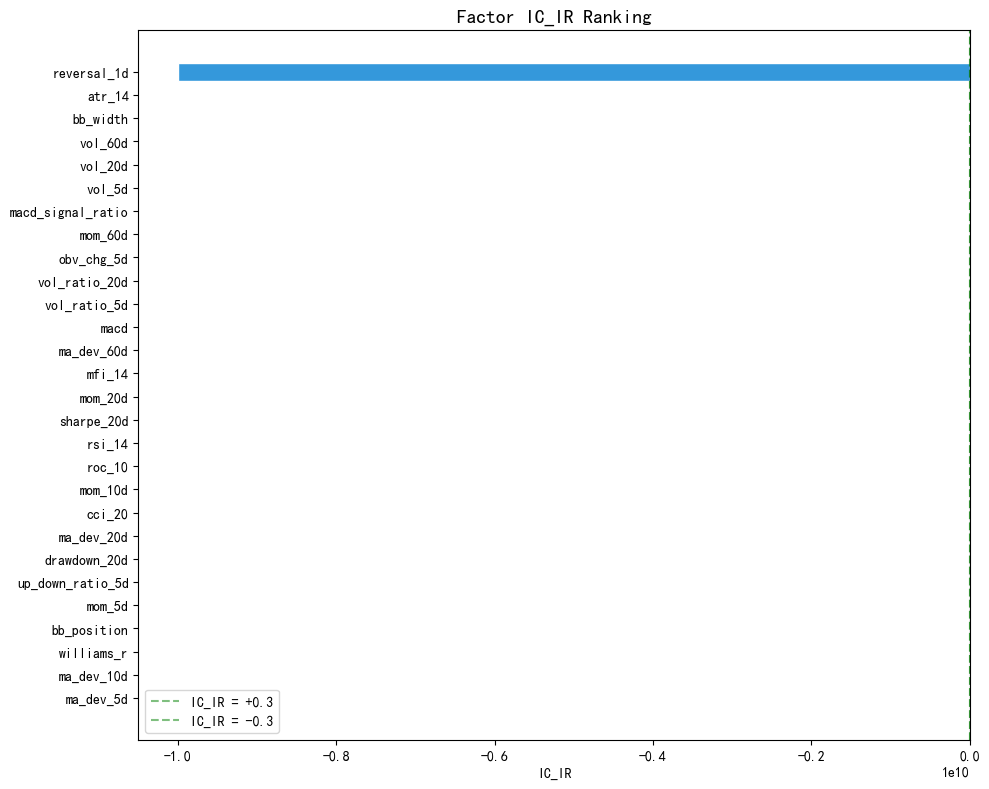

In [7]:
fig, ax = plt.subplots(figsize=(10, 8))

ic_sorted = ic_df.set_index('factor').sort_values('IC_IR')
colors = ['#e74c3c' if v > 0 else '#3498db' for v in ic_sorted['IC_IR'].values]

bars = ax.barh(range(len(ic_sorted)), ic_sorted['IC_IR'].values, color=colors, edgecolor='white')
ax.set_yticks(range(len(ic_sorted)))
ax.set_yticklabels(ic_sorted.index)
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
ax.axvline(x=0.3, color='green', linestyle='--', alpha=0.5, label='IC_IR = +0.3')
ax.axvline(x=-0.3, color='green', linestyle='--', alpha=0.5, label='IC_IR = -0.3')
ax.set_xlabel('IC_IR')
ax.set_title('Factor IC_IR Ranking', fontsize=14, fontweight='bold')
ax.legend()
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('results/03_ic_ir_ranking.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.3 关键因子IC时序图

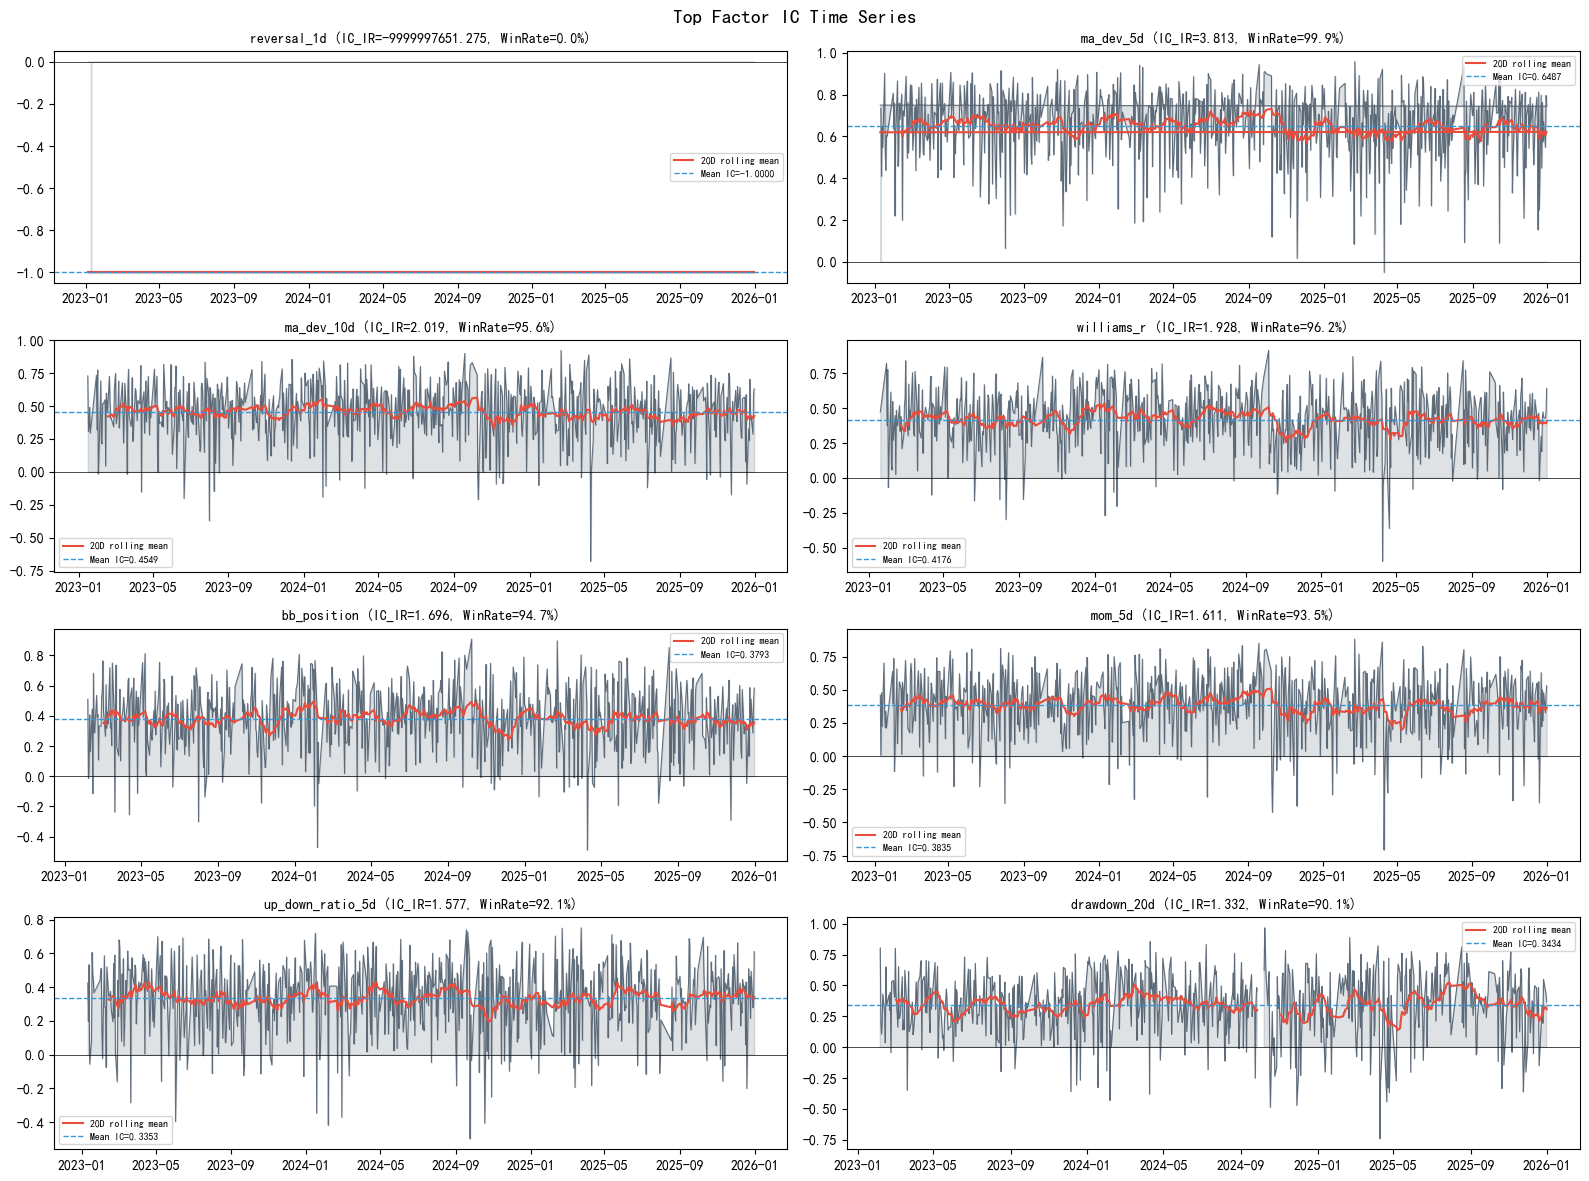

In [8]:
# 绘制IC_IR最高的前几个因子的IC序列
top_factors = ic_df.head(8)['factor'].tolist()

fig, axes = plt.subplots(4, 2, figsize=(16, 12))
axes = axes.flatten()

for i, fname in enumerate(top_factors):
    ax = axes[i]
    ic_series = ic_results[fname]
    
    # IC时序
    ax.plot(ic_series.index, ic_series.values, color='#2c3e50', linewidth=0.8, alpha=0.7)
    # 5日滚动平均
    rolling_ic = ic_series.rolling(20).mean()
    ax.plot(rolling_ic.index, rolling_ic.values, color='#e74c3c', linewidth=1.5, label='20D rolling mean')
    
    ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
    ax.axhline(y=ic_series.mean(), color='#3498db', linestyle='--', linewidth=1, label=f'Mean IC={ic_series.mean():.4f}')
    ax.fill_between(ic_series.index, 0, ic_series.values, alpha=0.15, color='#2c3e50')
    
    row = ic_df[ic_df['factor'] == fname].iloc[0]
    ax.set_title(f'{fname} (IC_IR={row["IC_IR"]:.3f}, WinRate={row["IC_winrate"]:.1%})', fontsize=10)
    ax.legend(fontsize=7)

fig.suptitle('Top Factor IC Time Series', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('results/03_ic_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. 分层回测（Factor Quantile Analysis）

In [9]:
def factor_quantile_returns(factor_name, n_groups=5):
    """
    对因子进行分层，计算各组的平均收益
    Group 1 = 因子值最小的组, Group N = 因子值最大的组
    """
    group_returns = {g: [] for g in range(1, n_groups + 1)}
    dates = factor_wide.index.get_level_values('date').unique()
    
    for date in dates:
        try:
            # MultiIndex: .loc[date] 返回 index=ticker 的 DataFrame
            f_cross = factor_wide.loc[date][factor_name].dropna()
            r_cross = ret_df.loc[date].dropna()
            
            common = f_cross.index.intersection(r_cross.index)
            if len(common) < n_groups * 3:
                continue
            
            f_vals = f_cross[common].astype(float)
            labels = pd.qcut(f_vals, n_groups, labels=False, duplicates='drop')
            
            for g in range(n_groups):
                g_mask = labels == g
                if g_mask.sum() > 0:
                    group_returns[g + 1].append({
                        'date': date,
                        'avg_ret': r_cross[common][g_mask].mean()
                    })
        except:
            continue
    
    # 构建各组收益序列
    result = {}
    for g in range(1, n_groups + 1):
        if len(group_returns[g]) == 0:
            result[f'G{g}'] = pd.Series(dtype=float)
        else:
            df = pd.DataFrame(group_returns[g]).set_index('date')['avg_ret']
            result[f'G{g}'] = df
    
    return pd.DataFrame(result)

In [10]:
%%time

# 对IC_IR绝对值最高的几个因子做分层分析
quantile_results = {}
top_abs_factors = ic_df.nlargest(6, 'abs_IC_IR')['factor'].tolist()

for fname in top_abs_factors:
    qret = factor_quantile_returns(fname, n_groups=5)
    quantile_results[fname] = qret
    
    # 计算多空收益差
    long_short = qret['G5'].mean() - qret['G1'].mean()
    print(f'{fname:<25s} Long-Short spread (G5-G1): {long_short:.6f} per day')

reversal_1d               Long-Short spread (G5-G1): -0.039910 per day
ma_dev_5d                 Long-Short spread (G5-G1): 0.028763 per day
ma_dev_10d                Long-Short spread (G5-G1): 0.021273 per day
williams_r                Long-Short spread (G5-G1): 0.018832 per day
bb_position               Long-Short spread (G5-G1): 0.018260 per day
mom_5d                    Long-Short spread (G5-G1): 0.018319 per day
CPU times: total: 14.4 s
Wall time: 14.4 s


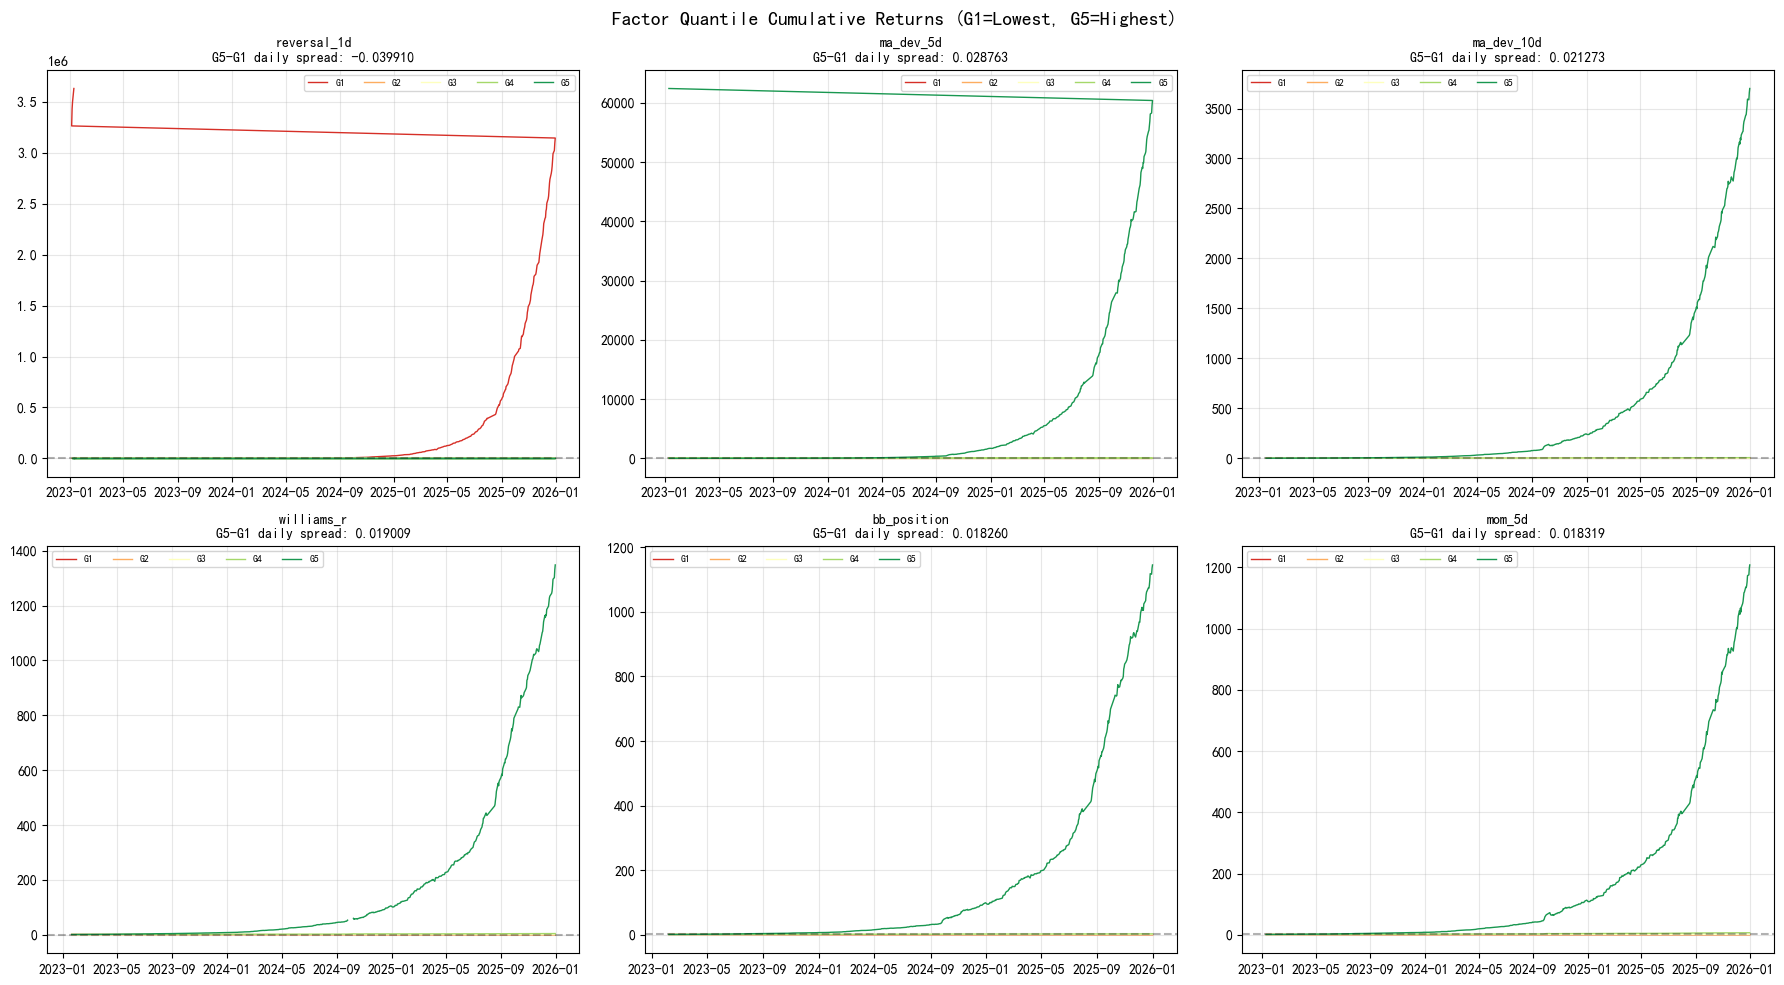

In [11]:
# ===== 分层回测可视化 =====
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

cmap = plt.cm.RdYlGn

for i, (fname, qret) in enumerate(quantile_results.items()):
    ax = axes[i]
    cum_ret = (1 + qret).cumprod()
    
    for j in range(5):
        color = cmap(0.1 + j * 0.2)
        ax.plot(cum_ret.index, cum_ret[f'G{j+1}'].values,
                color=color, linewidth=1, label=f'G{j+1}')
    
    ax.set_title(f'{fname}\nG5-G1 daily spread: {(qret["G5"] - qret["G1"]).mean():.6f}', fontsize=10)
    ax.legend(fontsize=7, ncol=5)
    ax.axhline(y=1.0, color='black', linestyle='--', alpha=0.3)
    ax.grid(True, alpha=0.3)

fig.suptitle('Factor Quantile Cumulative Returns (G1=Lowest, G5=Highest)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('results/03_quantile_returns.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. 因子相关性分析

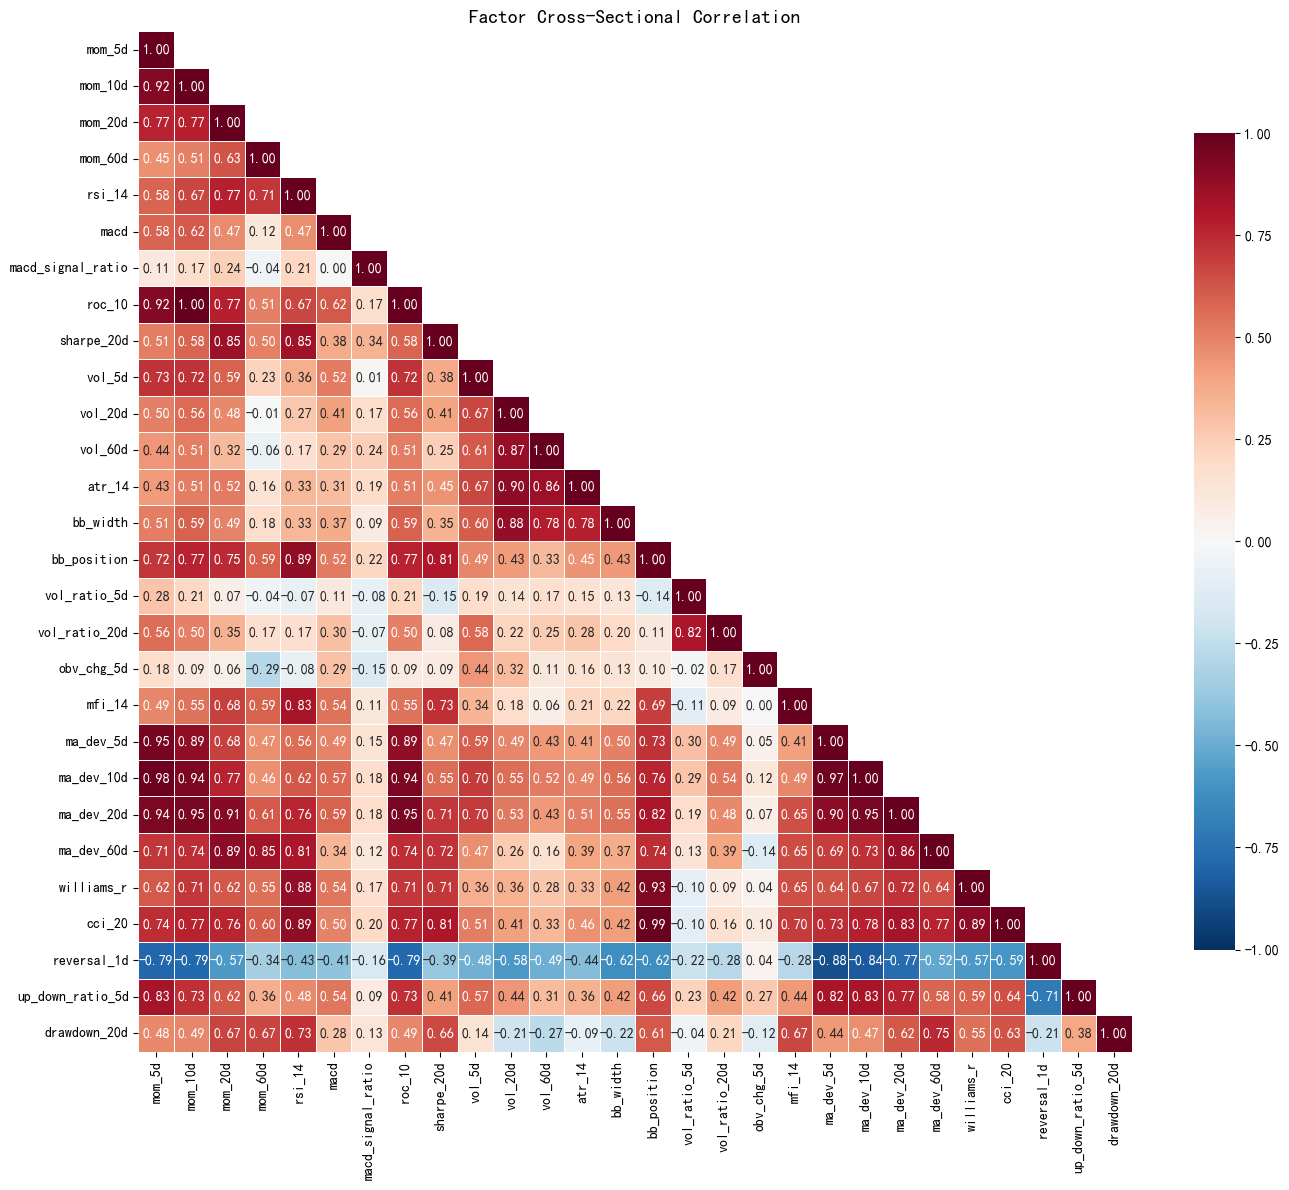

In [12]:
# 计算因子间的平均截面相关性
# 取最近一个截面的因子值
latest_date = factor_wide.index.get_level_values('date').max()
latest_factors = factor_wide.loc[latest_date].dropna(axis=1)

f_corr = latest_factors.corr()

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(f_corr, dtype=bool), k=1)
sns.heatmap(f_corr, mask=mask, cmap='RdBu_r', center=0,
            annot=True, fmt='.2f', linewidths=0.5,
            ax=ax, vmin=-1, vmax=1, cbar_kws={'shrink': 0.8})
ax.set_title('Factor Cross-Sectional Correlation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('results/03_factor_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. 因子筛选

根据以下标准筛选有效因子：
- |IC_IR| > 0.25
- IC胜率 > 55%
- 因子间相关系数 < 0.7（去冗余）

In [13]:
# 筛选条件
IC_IR_THRESHOLD = 0.25
WINRATE_THRESHOLD = 0.52
CORR_THRESHOLD = 0.7

# 第一轮筛选
filtered = ic_df[
    (ic_df['abs_IC_IR'] >= IC_IR_THRESHOLD) &
    (ic_df['IC_winrate'] >= WINRATE_THRESHOLD)
].copy()

print(f'IC筛选后: {len(filtered)}/{len(ic_df)} 个因子')

# 第二轮：去冗余（保留IC_IR更高的）
selected = []
used_factors = set()

for _, row in filtered.iterrows():
    fname = row['factor']
    # 检查是否与已选因子高度相关
    is_redundant = False
    for sf in selected:
        if fname in f_corr.columns and sf in f_corr.columns:
            if abs(f_corr.loc[fname, sf]) > CORR_THRESHOLD:
                is_redundant = True
                break
    if not is_redundant:
        selected.append(fname)

print(f'去冗余后: {len(selected)} 个独立有效因子')
print('\n选中的因子:')
for f in selected:
    row = filtered[filtered['factor'] == f].iloc[0]
    print(f'  ✓ {f:<22s} IC_IR={row["IC_IR"]:+.3f}, WinRate={row["IC_winrate"]:.1%}')

IC筛选后: 21/28 个因子
去冗余后: 9 个独立有效因子

选中的因子:
  ✓ ma_dev_5d              IC_IR=+3.813, WinRate=99.9%
  ✓ williams_r             IC_IR=+1.928, WinRate=96.2%
  ✓ drawdown_20d           IC_IR=+1.332, WinRate=90.1%
  ✓ mom_20d                IC_IR=+0.700, WinRate=76.0%
  ✓ mfi_14                 IC_IR=+0.625, WinRate=72.2%
  ✓ macd                   IC_IR=+0.553, WinRate=69.6%
  ✓ vol_ratio_5d           IC_IR=+0.549, WinRate=71.5%
  ✓ obv_chg_5d             IC_IR=+0.447, WinRate=67.8%
  ✓ mom_60d                IC_IR=+0.332, WinRate=63.9%


In [14]:
# 保存筛选结果
pd.Series(selected).to_csv('data/selected_factors.csv', index=False, header=['factor'])

print(f'✓ 有效因子列表已保存: data/selected_factors.csv ({len(selected)} factors)')

✓ 有效因子列表已保存: data/selected_factors.csv (9 factors)


## 小结

✅ 计算了所有因子的Rank IC序列
✅ 分析了IC_IR、IC胜率等统计指标
✅ 完成了分层回测验证因子单调性
✅ 因子相关性分析
✅ 筛选出有效的独立因子

下一步: [04_model.ipynb](./04_model.ipynb) 多因子模型构建